<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Low-Pass (Alçak Geçiren)       -> Ortalama Parlaklık: 124.37 (Girdi: 124.37)
High-Pass (Yüksek Geçiren)     -> Ortalama Parlaklık: 11.34 (Girdi: 124.37)
Band-Pass (Bant Geçiren)       -> Ortalama Parlaklık: 8.41 (Girdi: 124.37)
Band-Reject (Bant Durduran)    -> Ortalama Parlaklık: 124.37 (Girdi: 124.37)


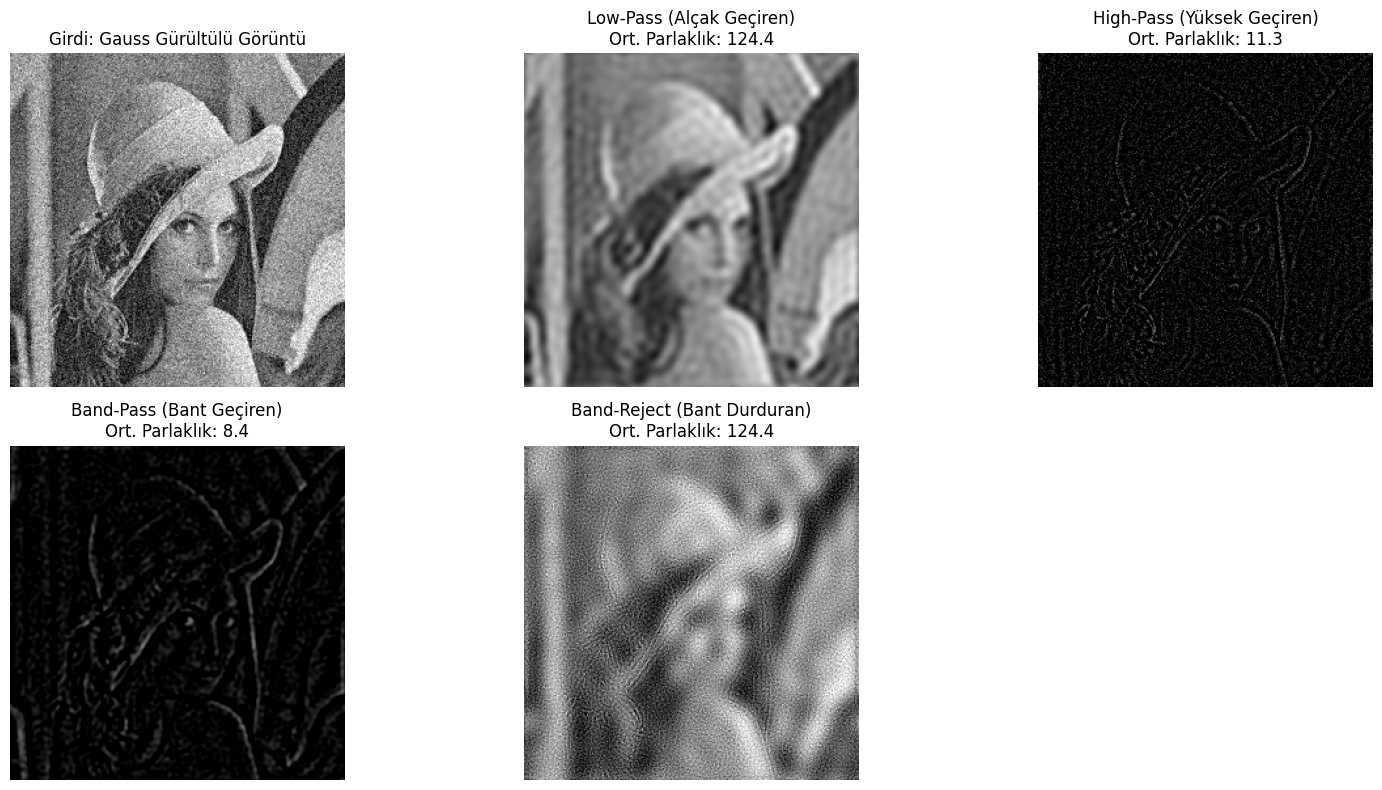

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

def gauss_gurultu_ekle(image, noise_strength=25.0, mean=0.0):
    img_float = np.asarray(image, dtype=np.float64)
    noisy = np.clip(img_float + np.random.normal(mean, noise_strength, size=img_float.shape), 0, 255)
    return noisy.astype(np.float64)

def salt_and_pepper_ekle(image, noise_ratio=0.06, salt_vs_pepper=0.5):
    noisy = np.asarray(image, dtype=np.uint8).copy()
    rnd = np.random.rand(*noisy.shape)
    noisy[rnd < (noise_ratio * salt_vs_pepper)] = 255
    noisy[(rnd >= (noise_ratio * salt_vs_pepper)) & (rnd < noise_ratio)] = 0
    return noisy.astype(np.float64)

def frekans_filtresi_uygula(image, filter_type="low_pass", d0=25.0, d1=15.0, d2=55.0):
    """
    2D frekans uzayında low_pass, high_pass, band_pass veya band_reject filtre uygular.
    filter_type : 'low_pass', 'high_pass', 'band_pass', 'band_reject'
    d0          : Low-pass / High-pass kesim yarıçapı (piksel frekans birimi)
    d1, d2      : Band-pass / Band-reject alt ve üst yarıçap sınırları (d1 < d2)
    """
    img = np.asarray(image, dtype=np.float64)
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2

    f_transform = np.fft.fft2(img)
    f_shift = np.fft.fftshift(f_transform)

    y_grid, x_grid = np.ogrid[:rows, :cols]
    dist = np.sqrt((x_grid - ccol) ** 2 + (y_grid - crow) ** 2)

    if filter_type == "low_pass":
        mask = (dist <= d0).astype(np.float64)
    elif filter_type == "high_pass":
        mask = (dist > d0).astype(np.float64)
    elif filter_type == "band_pass":
        mask = ((dist >= d1) & (dist <= d2)).astype(np.float64)
    elif filter_type == "band_reject":
        mask = ~((dist >= d1) & (dist <= d2))
        mask = mask.astype(np.float64)
    else:
        raise ValueError("Geçersiz filtre tipi. Seçenekler: low_pass, high_pass, band_pass, band_reject")

    filtered_shift = f_shift * mask
    f_ishift = np.fft.ifftshift(filtered_shift)
    img_back = np.real(np.fft.ifft2(f_ishift))

    return np.clip(img_back, 0, 255), mask

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img_color = cv2.imdecode(arr, cv2.IMREAD_COLOR)
img_gray = cv2.cvtColor(cv2.resize(img_color, (256, 256)), cv2.COLOR_BGR2GRAY).astype(np.float64)

img_gauss = gauss_gurultu_ekle(img_gray, noise_strength=25.0)
img_sp = salt_and_pepper_ekle(img_gray, noise_ratio=0.05)

target_img = img_gauss
target_name = "Gauss Gürültülü Görüntü"

filter_types = ["low_pass", "high_pass", "band_pass", "band_reject"]
titles = {
    "low_pass": "Low-Pass (Alçak Geçiren)",
    "high_pass": "High-Pass (Yüksek Geçiren)",
    "band_pass": "Band-Pass (Bant Geçiren)",
    "band_reject": "Band-Reject (Bant Durduran)"
}

plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(target_img, cmap='gray', vmin=0, vmax=255)
plt.title(f'Girdi: {target_name}')
plt.axis('off')

for idx, ftype in enumerate(filter_types, start=2):
    out_img, _ = frekans_filtresi_uygula(target_img, filter_type=ftype, d0=25.0, d1=12.0, d2=55.0)
    mean_orig = np.mean(target_img)
    mean_out = np.mean(out_img)
    print(f"{titles[ftype]:30s} -> Ortalama Parlaklık: {mean_out:.2f} (Girdi: {mean_orig:.2f})")

    plt.subplot(2, 3, idx)
    plt.imshow(out_img, cmap='gray', vmin=0, vmax=255)
    plt.title(f'{titles[ftype]}\nOrt. Parlaklık: {mean_out:.1f}')
    plt.axis('off')

plt.tight_layout()
plt.show()